<a href="https://colab.research.google.com/github/reitezuz/18NES2-2026/blob/main/week06/cats_dogs_small_Xception.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XCeption-like Convolutional Neural Network - classifying images from the Dogs vs. Cats Dataset

Inspired by:
  - https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter08_image-classification.ipynb
  - https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter09_convnet-architecture-patterns.ipynb

The Dogs vs. Cats dataset is a collection of images for binary image classification. It contains a training set of labeled images of cats and dogs, originally used in a Kaggle competition (2013). Each image is a color photo. The dataset provides a challenging problem of distinguishing between two visually similar categories and is widely used for experimenting with convolutional neural networks.

You can download the dataset from the following sources:
- https://www.kaggle.com/c/dogs-vs-cats
- https://www.microsoft.com/en-us/download/details.aspx?id=54765

We will work with a smaller dataset available at:
- http://zuzka.petricek.net/vyuka_2024/NES2_2024/data/cats_vs_dogs_small.zip

1. Download the zip file with the data
2. Extract the zip file

In [1]:
import requests
import zipfile
import os

zip_path = "cats_vs_dogs_small.zip"
url = "http://zuzka.petricek.net/vyuka_2024/NES2_2024/data/cats_vs_dogs_small.zip"
output_folder = "."

#base_folder ="cats_vs_dogs_small/"

# Download the zip file
response = requests.get(url)

# Save the zip file locally
with open(zip_path, "wb") as file:
    file.write(response.content)

# Extract the zip file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(output_folder)

# Clean up by removing the downloaded zip file
os.remove(zip_path)



## Process the data

### The required folder structure for image classification in Keras, TensorFlow and Pytorch
- The **root folder** should contain **three subdirectories**: `train`, `validation`, and `test`. The folders represent the essential division of the dataset into training, validation, and testing sets.
- Within each of these directories, images for separate classes are stored in **separate subfolders**. The name of each subfolder will be automatically used as the **class label**.

- This folder structure is required by Keras, TensorFlow, and PyTorch image loaders:
 - Keras functions such as `image_dataset_from_directory(directory)` or `flow_from_directory()`
  - PyTorch datasets such as `torchvision.datasets.ImageFolder`


### The format (structure) of the folder with data:
- in our case, the root folder contains three subdirectories: `train` (2000 images), `validation` (1000 images), and `test` (2000 images):

```
cats_vs_dogs_small/
├── train/
│   ├── Cat/
│   └── Dog/
├── validation/
│   ├── Cat/
│   └── Dog/
└── test/
│   ├── Cat/
│   └── Dog/
```

Observe the number of images in each folder:
- the dataset is balanced

In [2]:
import os

base_dir = "cats_vs_dogs_small"

for split in ["train", "validation", "test"]:
    split_dir = os.path.join(base_dir, split)
    print(f"\n{split.upper()}:")
    for category in ["Cat", "Dog"]:
        category_dir = os.path.join(split_dir, category)
        num_images = len(os.listdir(category_dir))
        print(f"  {category}: {num_images} images")


TRAIN:
  Cat: 1000 images
  Dog: 1000 images

VALIDATION:
  Cat: 500 images
  Dog: 500 images

TEST:
  Cat: 1000 images
  Dog: 1000 images


Observe some images:

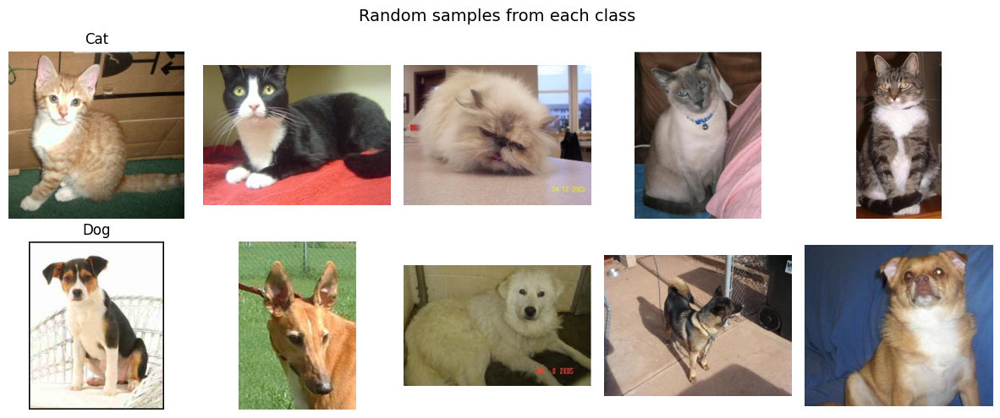

In [3]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

base_dir = "cats_vs_dogs_small/train"
classes = ["Cat", "Dog"]

fig, axes = plt.subplots(len(classes), 5, figsize=(12, 5))
fig.suptitle("Random samples from each class", fontsize=14)

for i, cls in enumerate(classes):
    class_dir = os.path.join(base_dir, cls)
    images = random.sample(os.listdir(class_dir), 5)

    for j, img_name in enumerate(images):
        img_path = os.path.join(class_dir, img_name)
        img = mpimg.imread(img_path)
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls)

plt.tight_layout()
plt.show()

### Create Datasets from folders
- **`image_dataset_from_directory(directory)`**:
 - available in Keras with TensorFlow backend only – not compatible with PyTorch)
  1. Assumes the folder structure follows the format: class-specific subfolders within `train`, `validation`, and `test` directories.
  2. Scans and indexes image files in each subdirectory, automatically assigning labels based on folder names.
  3. Returns a `tf.data.Dataset` object that:
     - Loads and shuffles the files,
     - Decodes images into tensors,
     - Resizes images to a consistent size,
     - Batches images for efficient model training and evaluation.


https://keras.io/api/data_loading/image/

In [4]:
image_size = (180, 180)
batch_size = 32

base_folder ="cats_vs_dogs_small/"

from keras.utils import image_dataset_from_directory
train_dataset = image_dataset_from_directory(
    base_folder + "train",
    image_size=image_size,
    seed=42,
    batch_size=batch_size)
validation_dataset = image_dataset_from_directory(
    base_folder  + "validation",
    image_size=image_size,
    seed=42,
    batch_size=batch_size)
test_dataset = image_dataset_from_directory(
    base_folder  + "test",
    image_size=image_size,
    shuffle = False,
    seed=42,
    batch_size=batch_size)



Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


- `tf.data.Dataset` is an iterator:

In [5]:
for data_batch, labels_batch in train_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break
for data_batch, labels_batch in validation_dataset:
    print("data batch shape:", data_batch.shape)
    print("labels batch shape:", labels_batch.shape)
    break

data batch shape: (32, 180, 180, 3)
labels batch shape: (32,)
data batch shape: (32, 180, 180, 3)
labels batch shape: (32,)


### More about tf.data.Dataset:

In [6]:
# Another example of a dataset:
import numpy as np
import tensorflow as tf
random_numbers = np.random.normal(size=(1000, 16))
dataset = tf.data.Dataset.from_tensor_slices(random_numbers)

# iteration over examples:
for i, element in enumerate(dataset):
    print(element.shape)
    if i >= 2:
        break

# iteration over batches:
batched_dataset = dataset.batch(32)
for i, element in enumerate(batched_dataset):
    print(element.shape)
    if i >= 2:
        break

# iteration over batches with map:
reshaped_dataset = dataset.map(lambda x: tf.reshape(x, (4, 4)))
for i, element in enumerate(reshaped_dataset):
    print(element.shape)
    if i >= 2:
        break

(16,)
(16,)
(16,)
(32, 16)
(32, 16)
(32, 16)
(4, 4)
(4, 4)
(4, 4)


## Define the model

### Simple Xception-like model


In [7]:
# Define the model architecture

import keras
from keras import layers

# Define the model architecture:
def get_model():

    data_augmentation = keras.Sequential(
        [
                layers.RandomFlip("horizontal"),
                layers.RandomRotation(0.1),
                layers.RandomZoom(0.2),
                layers.RandomContrast(0.1),
                layers.RandomBrightness(0.1),
                layers.RandomTranslation(0.1, 0.1),
        ]
    )

    inputs = keras.Input(shape=image_size + (3, ))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)
    x = layers.Conv2D(filters=32, kernel_size=5, use_bias=False)(x)

    for size in [32, 64, 128, 256, 512]:
        residual = x

        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same", use_bias=False)(x)

        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.SeparableConv2D(size, 3, padding="same", use_bias=False)(x)

        x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

        residual = layers.Conv2D(
            size, 1, strides=2, padding="same", use_bias=False)(residual)
        x = layers.add([x, residual])

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model
model = get_model()
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 180, 180,  │          0 │ input_layer[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 180, 180,  │          0 │ sequential[0][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 176, 176,  │      2,400 │ rescaling[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 176, 176,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 176, 176,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 176, 176,  │      1,312 │ activation[0][0]  │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 176, 176,  │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 176, 176,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 176, 176,  │      1,312 │ activation_1[0][… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 88, 88,    │          0 │ separable_conv2d… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 88, 88,    │      1,024 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 88, 88,    │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 88, 88,    │        128 │ add[0][0]         │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 88, 88,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_2  │ (None, 88, 88,    │      2,336 │ activation_2[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 88, 88,    │        256 │ separable_conv2d

 Total params: 721,857 (2.75 MB)

 Trainable params: 718,849 (2.74 MB)

 Non-trainable params: 3,008 (11.75 KB)

In [8]:
# Data frame for results
import pandas as pd

columns = ["Model Name", "Test Accuracy", "Test Loss", "Train Accuracy", "Train Loss", "Time (s)", "Epochs", "Details"]
results_df = pd.DataFrame(columns=columns)

In [9]:
# plot the training progress:
def plot_history(history):
    history_dict = history.history
    print(history_dict.keys())

    from matplotlib import pyplot as plt

    # Plot training & validation accuracy values
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

    # Plot training & validation loss values
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

## Train the model

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 180, 180,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 180, 180,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 180, 180,  │          0 │ sequential_1[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 176, 176,  │      2,400 │ rescaling_1[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 176, 176,  │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 176, 176,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_10 │ (None, 176, 176,  │      1,312 │ activation_10[0]… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 176, 176,  │        128 │ separable_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, 176, 176,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_11 │ (None, 176, 176,  │      1,312 │ activation_11[0]… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 88, 88,    │          0 │ separable_conv2d… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 88, 88,    │      1,024 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 88, 88,    │          0 │ max_pooling2d_5[… │
│                     │ 32)               │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 88, 88,    │        128 │ add_5[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 88, 88,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_12 │ (None, 88, 88,    │      2,336 │ activation_12[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 88, 88,    │        256 │ separable_conv2d

 Total params: 721,857 (2.75 MB)

 Trainable params: 718,849 (2.74 MB)

 Non-trainable params: 3,008 (11.75 KB)

Epoch 1/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 32s 255ms/step - accuracy: 0.5695 - loss: 0.6916 - val_accuracy: 0.5000 - val_loss: 0.6940
Epoch 2/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 203ms/step - accuracy: 0.6125 - loss: 0.6575 - val_accuracy: 0.5160 - val_loss: 0.6921
Epoch 3/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 206ms/step - accuracy: 0.5820 - loss: 0.6694 - val_accuracy: 0.5000 - val_loss: 0.7033
Epoch 4/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 205ms/step - accuracy: 0.6325 - loss: 0.6469 - val_accuracy: 0.5220 - val_loss: 0.6916
Epoch 5/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 203ms/step - accuracy: 0.6580 - loss: 0.6224 - val_accuracy: 0.5000 - val_loss: 0.7090
Epoch 6/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 205ms/step - accuracy: 0.6760 - loss: 0.6039 - val_accuracy: 0.5520 - val_loss: 0.6983
Epoch 7/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 211ms/step - accuracy: 0.6615 - loss: 0.6098 - val_accuracy: 0.5990 - val_loss: 0.6611
Epoch 8/100
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 209ms/step - accuracy: 0.6835 - loss: 0.5940 - 

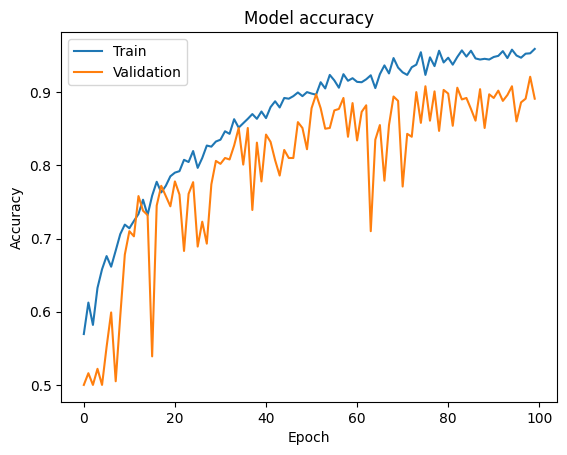

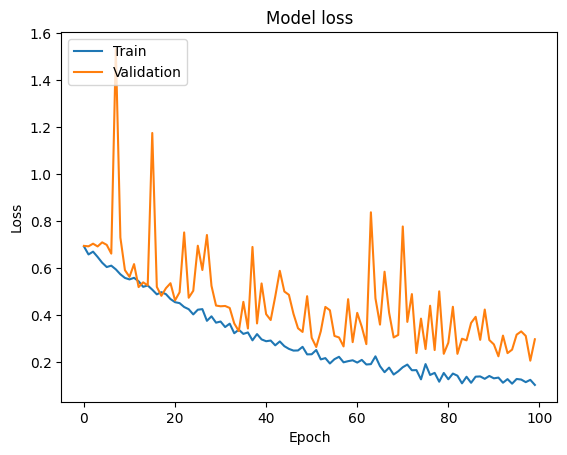

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9800 - loss: 0.0525
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9210 - loss: 0.2053
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9115 - loss: 0.2521
Training accuracy: 0.9800000190734863 
Train loss: 0.05254345387220383
Validation accuracy: 0.9210000038146973 
Val loss: 0.2053133249282837
Test accuracy: 0.9114999771118164 
Test loss: 0.25206953287124634
Results:


,Model Name,Details,Test Accuracy,Test Loss,Train Accuracy,Train Loss,Time (s),Epochs
0,cnn_catsdogs_small_Xception.keras,False-ep.:100-bs:32,0.9115,0.25207,0.98,0.052543,1421.018935,100


In [10]:
# Set some of the hyperparameters:
do_early_stopping = False
do_tensorboard = True
do_checkpoint = True
max_epochs = 100
model_name = 'cnn_catsdogs_small_Xception.keras'

details = "" # your comment

import keras
from keras import layers
import datetime

###############################################
# Define the model architecture:
model = get_model()
model.summary()

# Configure the model:
optimizer = keras.optimizers.Adam()
model.compile(optimizer=optimizer,
                  loss= keras.losses.BinaryCrossentropy(),
                  metrics= [keras.metrics.BinaryAccuracy("accuracy")])

###############################################
# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint =     keras.callbacks.ModelCheckpoint(
        filepath="./models/" + model_name,
        save_best_only=True,
        monitor="val_loss")
    callbacks.append(checkpoint)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_catsdogs/"+model_name, histogram_freq=1, write_steps_per_second=True)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_dataset, epochs=max_epochs,
                    validation_data=validation_dataset,
                    callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model("./models/" + model_name)

# Evaluate the model on the training, validation and test sets
train_loss, train_acc = model.evaluate(train_dataset)
val_loss, val_acc = model.evaluate(validation_dataset)
test_loss, test_acc = model.evaluate(test_dataset)

print('Training accuracy:', train_acc, '\nTrain loss:', train_loss)
print('Validation accuracy:', val_acc, '\nVal loss:', val_loss)
print('Test accuracy:', test_acc, '\nTest loss:', test_loss)

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
model_details = f"{do_early_stopping}-ep.:{max_epochs}-bs:{batch_size} {details}"
new_entry = {
    "Model Name" : model_name,
    "Details" : model_details,
    "Test Accuracy" : test_acc,
    "Test Loss" : test_loss,
    "Train Accuracy" : train_acc,
    "Train Loss" : train_loss,
    "Time (s)" : time_fit,
    "Epochs" : len(history.epoch),
}
if 'results_df' not in locals() or results_df is None or results_df.empty:
    results_df = pd.DataFrame([new_entry])
else:
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

# View and and save the dataframe:
results_df.to_csv(model_dir + "catsdogs_results.csv", index=False)
print("Results:")
display(results_df)


## Observations: Comparison of Xception-like and Bipyramidal Architectures
- The Xception-like model trains more slowly due to its greater depth and use of separable convolutions.
- It achieves a higher test accuracy (~90%) than the simpler bipyramidal CNN trained from scratch (typically 80–85%).
- However, its performance remains below that of transfer learning approaches, which is expected given the limited training data and randomly initialized weights.
- Compared to the bipyramidal model, it exhibits delayed and milder overfitting, reflecting a better balance between capacity and regularization.

## Confusion matrix and some misclassified images

Predicted labels: [np.float32(0.0), np.float32(0.0), np.float32(0.0), np.float32(0.0), np.float32(0.0), np.float32(0.0), np.float32(0.0), np.float32(1.0), np.float32(0.0), np.float32(0.0)]
True labels: [np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(0), np.int32(0)]
Number of misclassified images: 177 out of 2000 , accuracy: 0.9115


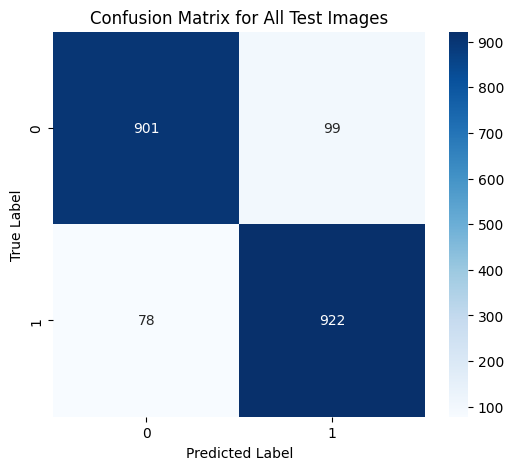

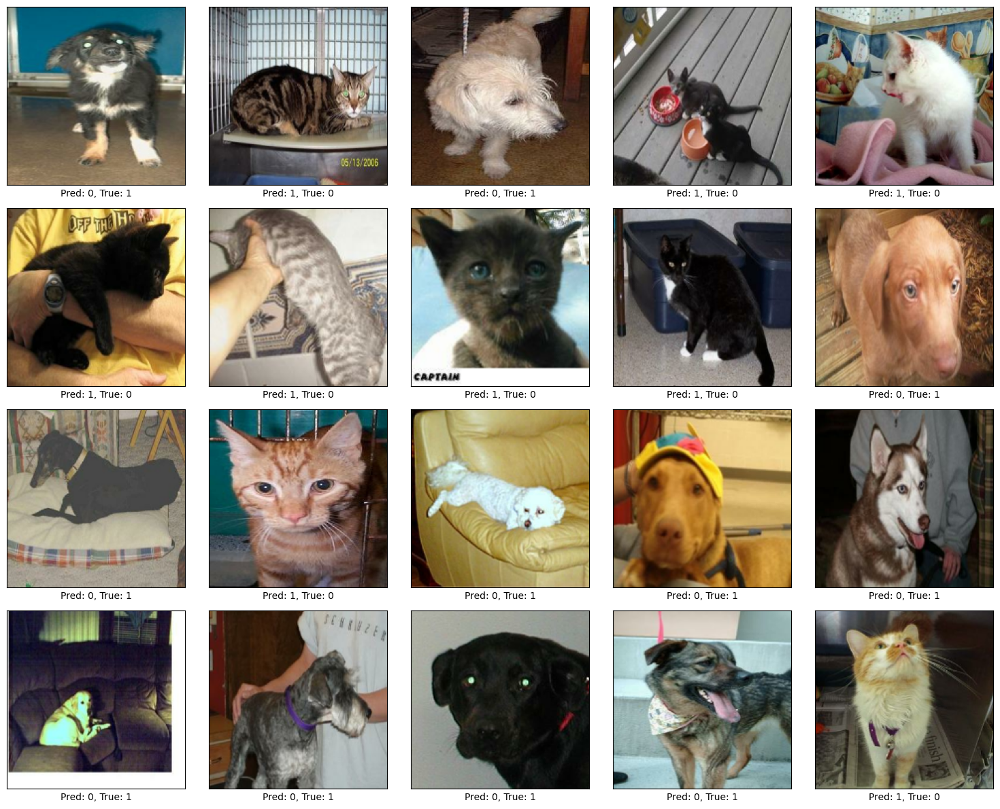

In [11]:
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import tensorflow as tf

y_true = []
y_pred = []
misclassified_images = []
misclassified_labels = []
misclassified_predictions = []


for images, labels in test_dataset:
    preds = model.predict(images, verbose=False)
    preds = tf.round(preds).numpy().flatten()
    y_true.extend(labels.numpy())
    y_pred.extend(preds)


    for i in range(len(images)):
        if preds[i] != labels[i].numpy():  # misclassified
            misclassified_images.append(images[i].numpy())
            misclassified_labels.append(labels[i].numpy())
            misclassified_predictions.append(int(preds[i]))

print("Predicted labels:", y_pred[:10])
print("True labels:", y_true[:10])

y_true = np.array(y_true)
y_pred = np.array(y_pred)
misclassified_images = np.array(misclassified_images)
misclassified_labels = np.array(misclassified_labels)
misclassified_predictions = np.array(misclassified_predictions)

# Calculate the number of misclassified images
misclassified_indices = np.where(y_pred != y_true)[0]
num_misclassified = len(misclassified_indices)
test_acc = (len(y_true) - num_misclassified) / len(y_true)
print("Number of misclassified images:", num_misclassified,
      "out of", len(y_true), ", accuracy:", test_acc)

# plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for All Test Images')
plt.show()

# plot some misclassified images
num_images_to_plot = 20
random_indices = random.sample(range(len(misclassified_images)), min(num_images_to_plot, len(misclassified_images)))

plt.figure(figsize=(15, 12))
for i, index in enumerate(random_indices):
    plt.subplot(4, 5, i + 1)  # 4 rows, 5 columns
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(misclassified_images[index].astype("uint8"))
    plt.xlabel(f"Pred: {misclassified_predictions[index]}, True: {misclassified_labels[index]}")
plt.tight_layout()
plt.show()


### Saliency map

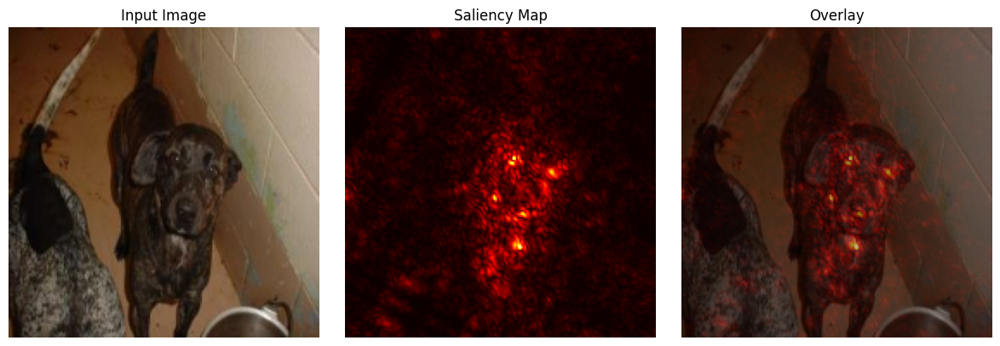

In [12]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

def visualize_saliency_map(model, image, label=None):
    """
    Generate a saliency map for an input RGB image,
    showing which pixels most affect the model's decision.
    """
    image_tensor = tf.convert_to_tensor(image[np.newaxis, ...], dtype=tf.float32)

    # Get prediction and inferred label if not provided
    predictions = model.predict(image_tensor, verbose=0)
    if label is None:
        label = tf.round(predictions).numpy().flatten()

    with tf.GradientTape() as tape:
        tape.watch(image_tensor)
        preds = model(image_tensor)
        loss = preds[:, 0]

    # Compute gradient of the output w.r.t. input image
    gradient = tape.gradient(loss, image_tensor)[0]

    # Saliency map: absolute max gradient across channels
    saliency = tf.reduce_max(tf.abs(gradient), axis=-1)

    # Normalize saliency to [0, 1]
    saliency = (saliency - tf.reduce_min(saliency)) / (tf.reduce_max(saliency) - tf.reduce_min(saliency) + 1e-8)
    saliency = saliency.numpy()

    # Convert image to displayable format if needed
    if image.max() <= 1.0:
        image_display = (image * 255).astype("uint8")
    else:
        image_display = image.astype("uint8")

    # Plotting
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.title("Input Image")
    plt.imshow(image_display)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Saliency Map")
    plt.imshow(saliency, cmap='hot')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Overlay")
    plt.imshow(image_display)
    plt.imshow(saliency, cmap='hot', alpha=0.5)
    plt.axis('off')

    plt.tight_layout()
    plt.show()


image_index = 1
# Get one image from the dataset
for images, labels in train_dataset.take(1):
    image = images[image_index].numpy()
    label = labels[image_index].numpy()
    break

# Call the saliency map function
visualize_saliency_map(model, image, label)

In [13]:
###############################################
# Load TensorBoard notebook extension
%load_ext tensorboard

# Start TensorBoard before training begins
%tensorboard --logdir logs_catsdogs  --reload_interval=1

<IPython.core.display.Javascript object>